## Chapter 09 - Determining How Much Data to Collect with Power Analyses

In this chapter we will learn how sample sizes influences our confidence in the accuracy of an Estimated Mean, and how to do a Power Analysis for a *t*-test.

In [1]:
import numpy as np
from scipy.stats import norm, expon
import seaborn as sns
from statsmodels.stats.power import TTestIndPower

### The effects of sample size on our confidence in the accuracy of an Estimated Mean

Here we will take samples from two distributions, the normal one and the exponential one, and show how the Estimated Means calculated from those samples tend to get better when the sample size is larger. We will start with showing how this works with the normal distribution.

First, let's start by drawing a normal distribution.

In [2]:
## Create an array of x-axis coordinates
x_axis = np.arange(start=-5,
                   stop=5.1,
                   step=0.1)
x_axis[:10]

array([-5. , -4.9, -4.8, -4.7, -4.6, -4.5, -4.4, -4.3, -4.2, -4.1])

In [3]:
## Create an array of y-axis coordinates that correspond to each value in x_axis
## NOTE: 'loc' = location = the mean. This is because the mean is also 
## called a "location parameter" since the mean determines the location of the center,
## or the highest point of the distribution.

## 'scale' = standard deviation, since the standard deviation is also called a "scale parameter"
## since the standard deviation scales the height of the distribution. The larger the
## standard deviation, the smaller the height.

y_axis = norm.pdf(x=x_axis,
                  loc=0,
                  scale=1)
y_axis[:10]

array([1.48671951e-06, 2.43896075e-06, 3.96129909e-06, 6.36982518e-06,
       1.01408521e-05, 1.59837411e-05, 2.49424713e-05, 3.85351967e-05,
       5.89430678e-05, 8.92616572e-05])

<Axes: >

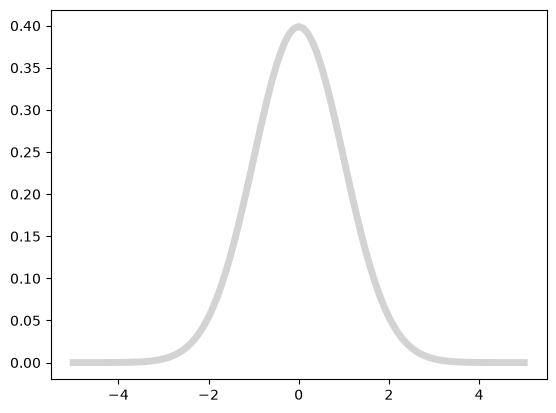

In [5]:
sns.lineplot(x=x_axis, y=y_axis, color='lightgrey', linewidth=5)

Now, let's add the estimated means, calculated with different sample sizes. We will start with n=1.

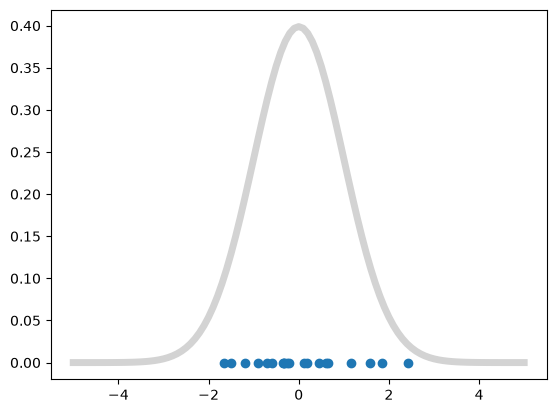

In [8]:
## First, make sure our results are reproduceable
np.random.seed(5)

num_rand_datasets = 20
num_datapoints = 1

means = np.empty(num_rand_datasets)

## Y_axis is just a bunch of 0s, one per estimated mean that we calculate,
## this simply to graphically place the estimated means at the bottom of our graph
y_axis_means = [0] * num_rand_datasets

## Now lets create num_rand_datasets datasets and calculate an estimated mean
## with each one
for i in range(num_rand_datasets):

    sample = np.random.normal(loc=0, scale=1, size=num_datapoints)
    means[i] = np.mean(sample)

## Now plot the normal distribution that the datasets where sampled from
my_curve = sns.lineplot(x=x_axis, y=y_axis,
                        color = 'lightgrey',
                        linewidth=5)

## and add on the estimated means
my_curve.scatter(means, y_axis_means)

Here we see that when n=1, the estimated means are spread out between -2 and 2.5. Now let's see what happens when we increase the sample size to n=2.

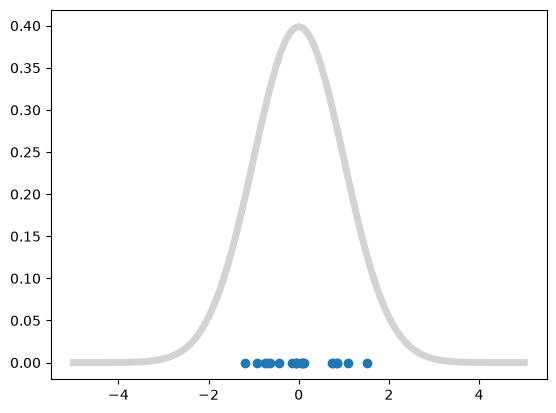

In [9]:
np.random.seed(5)

num_rand_datasets = 20
num_datapoints = 2

means = np.empty(num_rand_datasets)
y_axis_means = [0] * num_rand_datasets

for i in range(num_rand_datasets):
    
    sample = np.random.normal(loc=0, scale=1, size=num_datapoints)
    means[i] = np.mean(sample)

my_curve = sns.lineplot(x=x_axis, y=y_axis,
                        color='lightgrey',
                        linewidth=5)

my_curve.scatter(means, y_axis_means)

Now, when n=2, the estiamted means span a range of values from about -1.75 to 1.75. This is a narrower range of values than before. Let's try out n = 5.

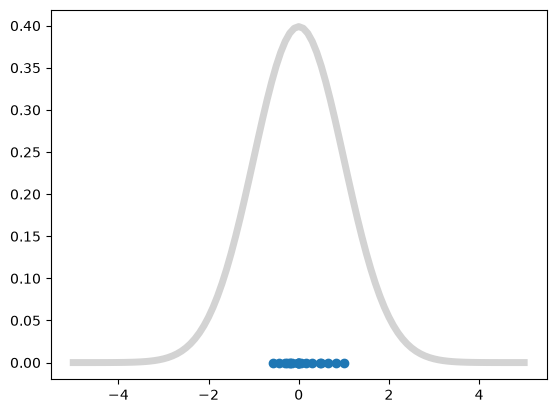

In [11]:
np.random.seed(5)

num_rand_datasets = 20
num_datapoints = 5

means = np.empty(num_rand_datasets)
y_axis_means = [0] * num_rand_datasets

for i in range(num_rand_datasets):
    
    sample = np.random.normal(loc=0, scale=1, size=num_datapoints)
    means[i] = np.mean(sample)

my_curve = sns.lineplot(x=x_axis, y=y_axis,
                        color='lightgrey',
                        linewidth=5)

my_curve.scatter(means, y_axis_means)

Setting the sample size to n = 5 resulted in the estimated means forming a tighter cluster around the Population Mean of 0. We see that each time we increase the sample size, the estimated mean clusters closer and closer to the true Population Mean. Thus, the larger the sample size the more confidence we can have that a particular estimated mean is close to the Population Mean.

Now that we have seen how increasing the sample size results in the Estimated mean being closer to the Population Mean for the Normal Distribution, let's see what happens when we use an Exponential Distribution – beginning with a sample size of n=1.

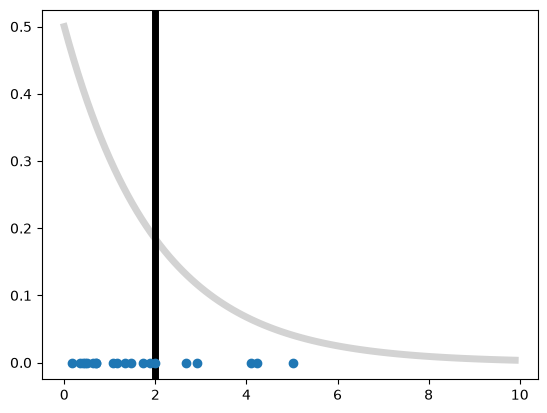

In [15]:
## Create the x- an y-axis coordinates for an exponential distribution
## with mean = 2.
exp_mean = 2

x_axis = np.arange(start=0, stop=10, step=0.1)

y_axis = expon.pdf(x_axis, scale=exp_mean)

my_curve = sns.lineplot(x=x_axis, y=y_axis,
                        color='lightgrey',
                        linewidth=5)

my_curve.axvline(x=exp_mean,
                 color='black',
                 linewidth=5)

np.random.seed(5)

num_rand_datasets = 20
num_datapoints = 1

means = np.empty(num_rand_datasets)
y_axis_means = [0] * num_rand_datasets

for i in range(num_rand_datasets):

    sample = np.random.exponential(scale=exp_mean,
                                   size=num_datapoints)
    means[i] = np.mean(sample)

my_curve.scatter(means,
                 y_axis_means,
                 zorder=10) ## We add 'zorder=10' to force python to draw the 
                            ## means on top of everything else

Now we know how to draw an exponential distribution and a vertical line at mean value, alongside adding the Estimated Means for the case with the sample size n=1.

Let's compare this with a sample size of n=2, and one of n=5.

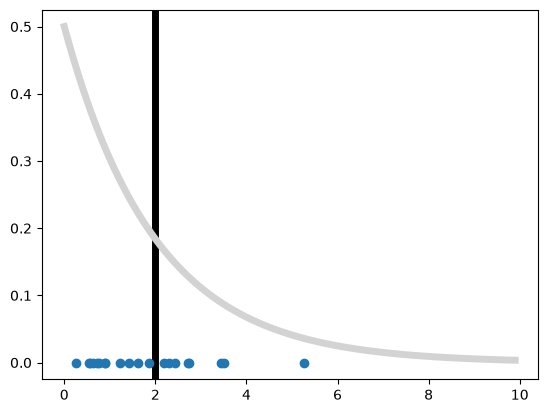

In [16]:
np.random.seed(5)

num_rand_datasets = 20
num_datapoints = 2

means = np.empty(num_rand_datasets)
y_axis_means = [0] * num_rand_datasets

for i in range(num_rand_datasets):
    
    sample = np.random.exponential(scale=exp_mean, size=num_datapoints)
    means[i] = np.mean(sample)

my_curve = sns.lineplot(x=x_axis, y=y_axis,
                        color='lightgrey',
                        linewidth=5)

my_curve.axvline(x=exp_mean, 
                 color="black",
                 linewidth=5,
                 zorder=0)

my_curve.scatter(means, 
                 y_axis_means, 
                 zorder=10)

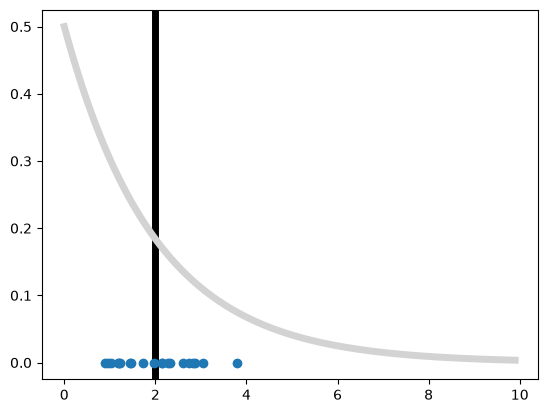

In [19]:
np.random.seed(5)

num_rand_datasets = 20
num_datapoints = 5

means = np.empty(num_rand_datasets)
y_axis_means = [0] * num_rand_datasets

for i in range(num_rand_datasets):
    
    sample = np.random.exponential(scale=exp_mean, size=num_datapoints)
    means[i] = np.mean(sample)

my_curve = sns.lineplot(x=x_axis, y=y_axis,
                        color='lightgrey',
                        linewidth=5)

my_curve.axvline(x=exp_mean, 
                 color="black",
                 linewidth=5,
                 zorder=0)

my_curve.scatter(means, 
                 y_axis_means, 
                 zorder=10)

What becomes evident is that the spread only materialy decreases with the sample size set to n = 5, given this seed. At n=10 (not displayed), the Estimated Means begin to cluster more tightly around the Popualtion Mean (as to be more visible).

### How to do a Power Analysis for *t*-tests

When experimenting, it is a good idea to determine if the sample size will be large enough to reject the null hypothesis, if the null hypothesis is, indeed, false. In other words, you should always do a **Power Analysis** before investing in an experiment.

To do a **Power Analysis** for a *t*-test in Python, we can use the `TTestIndPower()` function and it's `solve_power` method. We will start by using standard parameter values ($\beta = 0.80$, and $\alpha = 0.05$), and then compare with a case where we have a smaller standard deviation.

The last two things we need to specify are our estimates of the Difference for the Population Means and Standard Deviation for our two distributions. For this example, let's assume the difference in the Population Means is 1, and the difference in Standard Deviation is also 1. That makes the *effect size* equal to 1/1=1.

In [20]:
## create a t-test power analysis object
analysis = TTestIndPower()

## do a power analysis
analysis.solve_power(effect_size=1/1, power=0.80, alpha=0.05)

16.714722446954013

The output tells us that we need exactly 16.7 observations *in each group*, so 17+17=34 observations in total.

Let's compare that value to what we get when our estimate of the Standard Deviation is smaller, say 0.5.

In [21]:
analysis.solve_power(effect_size=1/0.5, power=0.8, alpha=0.05)

5.0899945682322505

So, when the estimated standard deviation is halfed, the number of measurements required to get the power we want (80% probability that we will correctly reject the null hypothesis if it is false) drops by over 60%. Instead of gathering 17 measurements per group, now we just need 5.